# Test the radius after a change of units
Run with OneSimulation, NumPy and Matplotlib installed.
Replace a starting coordinate by a smaller positive value. Recheck the certificate before iterating.

beta=0.105556, L=1.111111, certified radius=0.112599


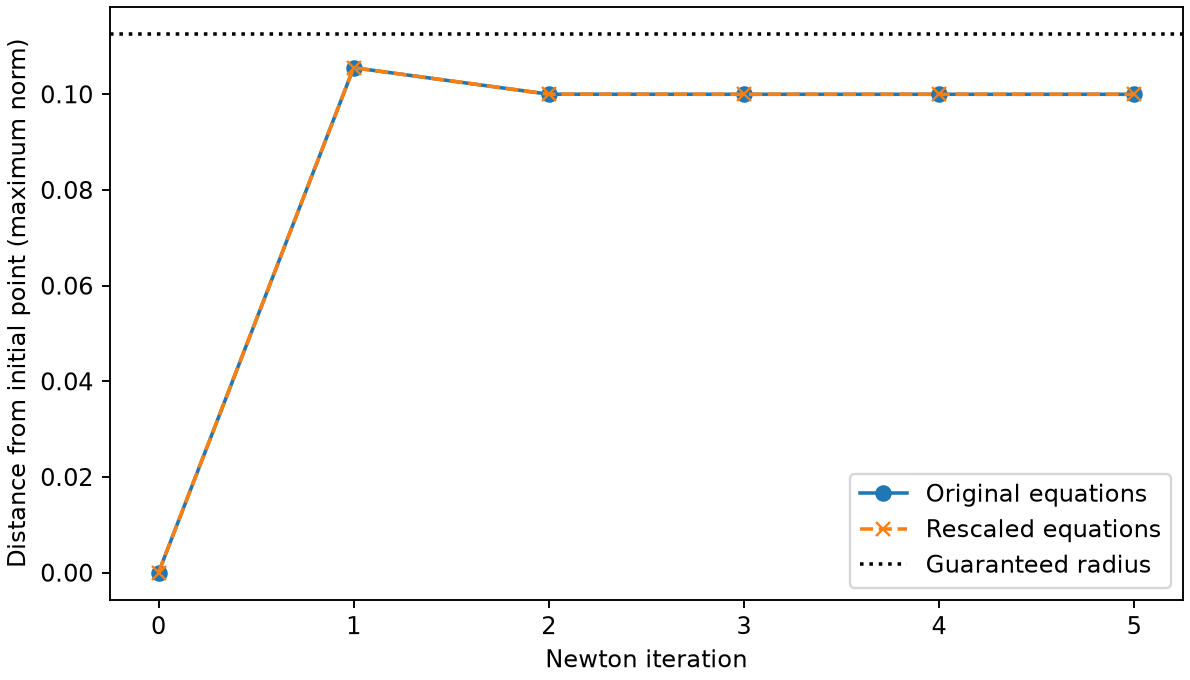

In [1]:
"""Test a Newton certificate without knowing the solution in advance."""
import matplotlib.pyplot as plt
import numpy as np
from onesim.numerics.linear.matrices.dense_linear_algebra import solve_dense

start = np.array([1.5, 0.9])
target = np.array([2.0, 1.0])
beta = np.linalg.norm((start**2 - target) / (2 * start), np.inf)
lipschitz = max(1 / start)
radius = 2 * beta / (1 + np.sqrt(1 - 2 * beta * lipschitz))
print(f"beta={beta:.6f}, L={lipschitz:.6f}, certified radius={radius:.6f}")
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for label, scale in [("Original equations", [1., 1.]), ("Rescaled equations", [1e4, 0.01])]:
    x = start.copy()
    distances = [0.0]
    for _ in range(5):
        residual = np.asarray(scale) * (x*x - target)
        jacobian = np.diag(2 * np.asarray(scale) * x)
        x -= solve_dense(jacobian, residual)
        distances.append(np.linalg.norm(x-start, np.inf))
    assert max(distances) <= radius and np.allclose(x**2, target)
    ax.plot(distances, "o-" if scale[0] == 1 else "x--", label=label)
ax.axhline(radius, color="black", ls=":", label="Guaranteed radius")
ax.set(xlabel="Newton iteration", ylabel="Distance from initial point (maximum norm)")
ax.legend()
fig.savefig("numerics-certified-newton.png", dpi=170)
